In [1]:
from __future__ import annotations
from pathlib import Path
import pandas as pd
import numpy as np
import re
import seaborn as sns
import matplotlib.pyplot as plt

import sys
modules_path = Path.cwd().parent / "modules"
sys.path.append(str(modules_path))
import basicmlp
from load_results import load_results, save_cache

In [2]:
date="20260625"

### Import Datasets and Embeddings

In [3]:
results_df= load_results("../07_OUTPUTS/", date=date)
save_cache(results_df, outputs_root="../07_OUTPUTS/", date=date)

PosixPath('../07_OUTPUTS/20260625/compiled/results.parquet')

In [4]:
results_df[results_df["dataset"]=="MQM_IS"]

,date,dataset_from_path,model_from_path,embedding_from_path,split_dir,summary_path,split_method_from_path,split_seed_from_path,dataset,model,...,outdir,train_MAE,train_RMSE,train_R2,test_MAE,test_RMSE,test_R2,train_MSE,test_MSE,run_id


In [5]:
df = results_df.copy() #[results_df["model"] == "linear"].copy()

# remove values with rmse > 100
df = df[df["test_R2"] > -0.5]

renamed_embeddings = {
    "morgan_fps": "ECFP4",
    "hq_descriptor": "QU",
    "chemeleon": "CheMeleon",
    "molclr": "MolCLR",
    "maceoff_large": "MACE OFF",
}

df["embedding"] = df["embedding"].map(renamed_embeddings)

desired_order_clean = [
    "ECFP4",
    "QU",
    "CheMeleon",
    "MolCLR",
    "MACE OFF"
]
df["embedding"] = pd.Categorical(df["embedding"], categories=desired_order_clean, ordered=True)

renamed_models = {
    "linear": "LR",
    "rf": "RF",
    "xgboost": "XGB",
    "mlp": "MLP",
}

desired_model_order = [
    "LR",
    "RF",
    "XGB",
    "MLP",
]
df["model"] = df["model"].map(renamed_models)
df["model"] = pd.Categorical(df["model"], categories=desired_model_order, ordered=True)


renamed_dataset = {
    "CD": r"$\rho_{cryst}$"
}
df["dataset"] = df["dataset"].map(renamed_dataset).fillna(df["dataset"])
desired_dataset_order = [
    r"$\rho_{cryst}$",
    "HOF",
    "IS",
]
df["dataset"] = pd.Categorical(df["dataset"], categories=desired_dataset_order, ordered=True)


/tmp/ipykernel_60646/1194568007.py:29: UserWarning: The palette list has more values (10) than needed (5), which may not be intended.
  sns.barplot(
/tmp/ipykernel_60646/1194568007.py:29: UserWarning: The palette list has more values (10) than needed (5), which may not be intended.
  sns.barplot(
/tmp/ipykernel_60646/1194568007.py:29: UserWarning: The palette list has more values (10) than needed (5), which may not be intended.
  sns.barplot(


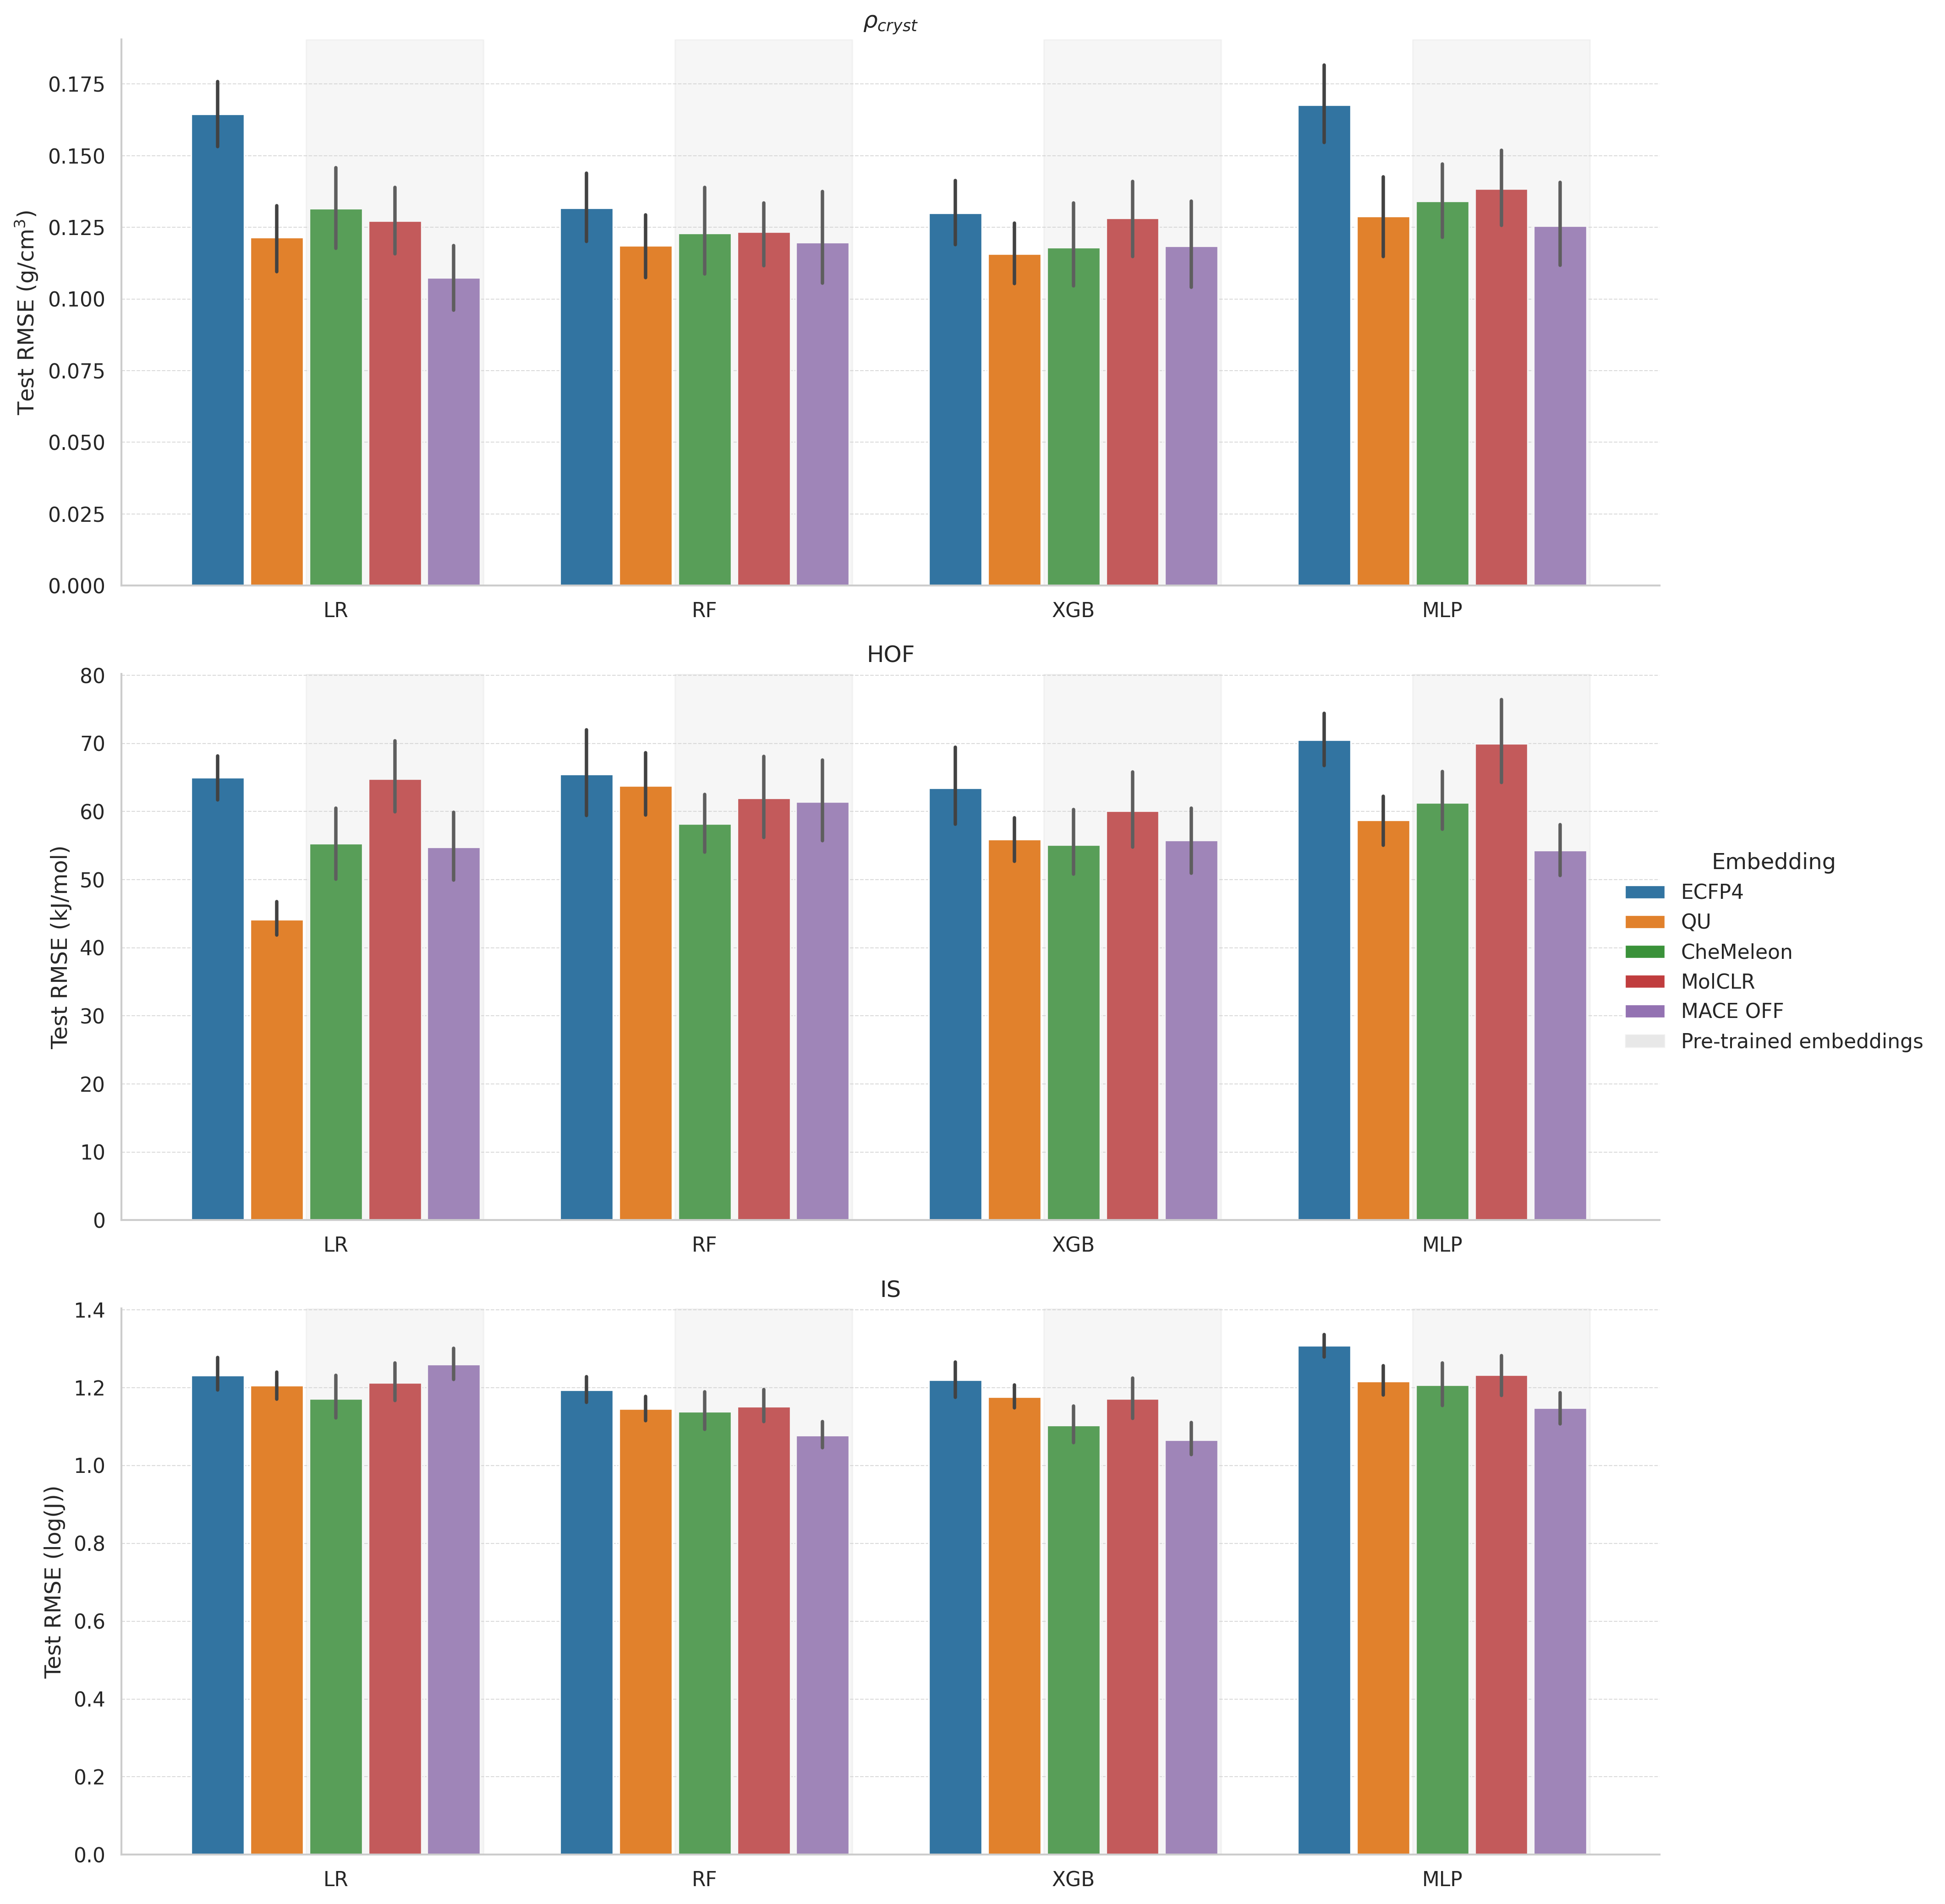

In [6]:
from matplotlib.patches import Patch

# Publication-style defaults
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)

palette = sns.color_palette("tab10")
datasets = desired_dataset_order
models = desired_model_order

embedding_order = [
    "ECFP4",
    "QU",
    "CheMeleon",
    "MolCLR",
    "MACE OFF",
]
pretrained_embeddings = {"CheMeleon", "MolCLR", "MACE OFF"}

fig, axes = plt.subplots(
    len(datasets), 1, figsize=(14, 14), sharey=False, dpi=300
)

legend_handles = None
legend_labels = None

for ax, ds in zip(axes, datasets):
    sub = df[df["dataset"] == ds]

    sns.barplot(
        data=sub,
        x="model",
        y="test_RMSE",
        hue="embedding",
        hue_order=embedding_order,
        palette=palette,
        errorbar="ci",
        ax=ax,
        gap=0.1
    )

    # Shade the contiguous pre-trained embeddings within each model group.
    n_embeddings = len(embedding_order)
    group_width = 0.8
    bar_width = group_width / n_embeddings
    pretrained_start = min(
        embedding_order.index(name) for name in pretrained_embeddings
    )
    pretrained_end = max(
        embedding_order.index(name) for name in pretrained_embeddings
    )

    for x_position in ax.get_xticks():
        left = (
            x_position
            - group_width / 2
            + pretrained_start * bar_width
        )
        right = (
            x_position
            - group_width / 2
            + (pretrained_end + 1) * bar_width
        )

        ax.axvspan(
            left,
            right,
            color="lightgray",
            alpha=0.2,
            zorder=0,
        )

    # Ensure bars and their error bars appear above the shading.
    for patch in ax.patches:
        patch.set_zorder(2)
    for container in ax.containers:
        if hasattr(container, "errorbar") and container.errorbar is not None:
            for artist_group in container.errorbar.lines:
                if artist_group:
                    for artist in artist_group:
                        artist.set_zorder(3)

    ax.set_title(f"{ds}", fontsize=12)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
    ax.grid(True, axis="y", linestyle="--", linewidth=0.5, alpha=0.7)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    if ax is axes[0]:
        ax.set_ylabel("Test RMSE (g/cm$^3$)")
    elif ax is axes[1]:
        ax.set_ylabel("Test RMSE (kJ/mol)")
    else:
        ax.set_ylabel("Test RMSE (log(J))")

    if legend_handles is None:
        legend_handles, legend_labels = ax.get_legend_handles_labels()

    ax.legend_.remove()

# Add shading entry to the shared legend.
legend_handles.append(
    Patch(
        facecolor="lightgray",
        alpha=0.5,
        label="Pre-trained embeddings",
    )
)
legend_labels.append("Pre-trained embeddings")

fig.legend(
    legend_handles,
    legend_labels,
    loc="center left",
    bbox_to_anchor=(0.84, 0.5),
    frameon=False,
    title="Embedding",
)

plt.tight_layout(rect=[0, 0, 0.88, 1])
plt.show()

# Comparison across regressors

In [7]:
df_clean = df[["dataset", "model", "seed", "split_method", "embedding", "test_MAE", "test_RMSE", "test_R2"]].copy()
df_clean = df_clean[df_clean["dataset"].isin(['HOF', "IS", "MQM_IS", r'$\rho_{cryst}$'])]
#df_clean.to_csv("../07_OUTPUTS/20260425/compiled/clean_results.csv", index=False)

In [8]:
df_clean.groupby(["dataset", "embedding"])[["test_RMSE", "test_R2"]].agg(["mean", "std"]).round(3)

/tmp/ipykernel_60646/3706031376.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_clean.groupby(["dataset", "embedding"])[["test_RMSE", "test_R2"]].agg(["mean", "std"]).round(3)


test_RMSE         test_R2       
                              mean     std    mean    std
dataset        embedding                                 
$\rho_{cryst}$ ECFP4         0.147   0.045   0.208  0.210
               QU            0.121   0.041   0.419  0.158
               CheMeleon     0.127   0.049   0.359  0.238
               MolCLR        0.129   0.045   0.352  0.243
               MACE OFF      0.118   0.053   0.465  0.246
HOF            ECFP4        65.886  17.075   0.397  0.348
               QU           55.599  14.784   0.515  0.286
               CheMeleon    57.464  16.793   0.506  0.305
               MolCLR       64.246  19.605   0.429  0.364
               MACE OFF     56.672  17.843   0.512  0.300
IS             ECFP4         1.235   0.140   0.083  0.235
               QU            1.185   0.123   0.149  0.174
               CheMeleon     1.153   0.184   0.183  0.260
               MolCLR        1.190   0.172   0.127  0.269
               MACE OFF      1.130   0.157   0.217  0.233

### Are the FMs equal to or better than the hand-crafted descriptor?

One-sided paired t-test on matched split and model-seed runs. Lower RMSE is better. The result is significant only when HC has significantly lower RMSE than the FM; otherwise, the FM is treated as equal or better.

In [9]:
from scipy.stats import ttest_rel

In [10]:
ALPHA = 0.05
FM_EMBEDDINGS = ["CheMeleon", "MolCLR", "MACE OFF"]
# select random splits only
df_random_splits = df_clean[df_clean["split_method"].str.contains("random", case=False, na=False)].copy()
# aggregate across models, comparing each FM embedding to the hand-crafted QU descriptors
model_aggregated = df_random_splits.groupby(["dataset", "model", "embedding", "seed", "split_method"])[["test_RMSE"]].mean().reset_index()
# xgb = df_clean[df_clean["model"] == "XGB"].copy()

records = []
for dataset in model_aggregated["dataset"].unique():
    dataset_scores = model_aggregated[model_aggregated["dataset"] == dataset]
    hc = (
        dataset_scores[dataset_scores["embedding"] == "QU"]
        [["split_method", "seed", "test_RMSE"]]
        .rename(columns={"test_RMSE": "hc_RMSE"})
    )

    for fm in FM_EMBEDDINGS:
        fm_scores = (
            dataset_scores[dataset_scores["embedding"] == fm]
            [["split_method", "seed", "test_RMSE"]]
            .rename(columns={"test_RMSE": "fm_RMSE"})
        )
        paired = fm_scores.merge(
            hc, on=["split_method", "seed"], how="inner"
        ).dropna()
        if len(paired) < 2:
            raise ValueError(f"Need at least two paired runs for {dataset=}, {fm=}")

        test = ttest_rel(
            paired["hc_RMSE"], paired["fm_RMSE"], alternative="less"
        )

        records.append({
            "dataset": dataset,
            "embedding": fm,
            "n_pairs": len(paired),
            "mean_hc_RMSE": paired["hc_RMSE"].mean(),
            "mean_fm_RMSE": paired["fm_RMSE"].mean(),
            "t_stat": test.statistic,
            "p_value": test.pvalue,
            "significance": "significant" if test.pvalue < ALPHA else "not significant",
            "result": "HC better than FM" if test.pvalue < ALPHA else "FM equal or better than HC",
        })

comparison_results = pd.DataFrame(records)

/tmp/ipykernel_60646/1093642106.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  model_aggregated = df_random_splits.groupby(["dataset", "model", "embedding", "seed", "split_method"])[["test_RMSE"]].mean().reset_index()


In [11]:
comparison_results

,dataset,embedding,n_pairs,mean_hc_RMSE,mean_fm_RMSE,t_stat,p_value,significance,result
0,$\rho_{cryst}$,CheMeleon,400,0.120203,0.124071,-4.752220,1.406378e-06,significant,HC better than FM
1,$\rho_{cryst}$,MolCLR,400,0.120203,0.122471,-3.708291,1.190992e-04,significant,HC better than FM
2,$\rho_{cryst}$,MACE OFF,400,0.120203,0.111559,15.257289,1.000000e+00,not significant,FM equal or better than HC
3,HOF,CheMeleon,400,53.069115,54.504922,-2.101552,1.810952e-02,significant,HC better than FM
4,HOF,MolCLR,400,53.069115,59.297479,-9.533632,7.598247e-20,significant,HC better than FM
5,HOF,MACE OFF,400,53.069115,52.663412,0.634653,7.369908e-01,not significant,FM equal or better than HC
6,IS,CheMeleon,400,1.121782,1.034353,27.915453,1.000000e+00,not significant,FM equal or better than HC
7,IS,MolCLR,400,1.121782,1.064325,16.269404,1.000000e+00,not significant,FM equal or better than HC
8,IS,MACE OFF,380,1.122678,1.035668,16.497295,1.000000e+00,not significant,FM equal or better than HC


In [12]:
one_table = (
    comparison_results
    .sort_values(["dataset", "embedding"])
    .rename(columns={
        "dataset": "Dataset",
        "embedding": "FM",
        "n_pairs": "Paired runs",
        "mean_hc_RMSE": "HC mean RMSE",
        "mean_fm_RMSE": "FM mean RMSE",
        "t_stat": "t statistic",
        "p_value": "p value",
        "significance": "Significance",
        "result": "Result",
    })
)

In [13]:
display(one_table.set_index(["Dataset", "FM"]).round(3))

Paired runs  HC mean RMSE  FM mean RMSE  \
Dataset        FM                                                   
$\rho_{cryst}$ CheMeleon          400         0.120         0.124   
               MACE OFF           400         0.120         0.112   
               MolCLR             400         0.120         0.122   
HOF            CheMeleon          400        53.069        54.505   
               MACE OFF           400        53.069        52.663   
               MolCLR             400        53.069        59.297   
IS             CheMeleon          400         1.122         1.034   
               MACE OFF           380         1.123         1.036   
               MolCLR             400         1.122         1.064   

                          t statistic  p value     Significance  \
Dataset        FM                                                 
$\rho_{cryst}$ CheMeleon       -4.752    0.000      significant   
               MACE OFF        15.257    1.000  not significant   
               MolCLR          -3.708    0.000      significant   
HOF            CheMeleon       -2.102    0.018      significant   
               MACE OFF         0.635    0.737  not significant   
               MolCLR          -9.534    0.000      significant   
IS             CheMeleon       27.915    1.000  not significant   
               MACE OFF        16.497    1.000  not significant   
               MolCLR          16.269    1.000  not significant   

                                              Result  
Dataset        FM                                     
$\rho_{cryst}$ CheMeleon           HC better than FM  
               MACE OFF   FM equal or better than HC  
               MolCLR              HC better than FM  
HOF            CheMeleon           HC better than FM  
               MACE OFF   FM equal or better than HC  
               MolCLR              HC better than FM  
IS             CheMeleon  FM equal or better than HC  
               MACE OFF   FM equal or better than HC  
               MolCLR     FM equal or better than HC

# win count table

In [14]:
def embedding_wins_and_avg_rank(
    df: pd.DataFrame,
    metric: str = "test_MAE",
    group_cols=("model", "dataset",),
    method: str = "average",  # rank tie handling
):
    d = df.copy()

    # Rank embeddings within each (dataset, model, seed, Split Method)
    d["rank"] = d.groupby(list(group_cols))[metric].rank(method=method, ascending=True)

    # Win = rank == 1 (ties count as wins for all tied embeddings)
    d["win"] = (d["rank"] == 1).astype(int)

    return d.groupby(["embedding"]).agg(
        win_count=("win", "sum"),
        avg_rank=("rank", "mean"),
    ).sort_values(["win_count", "avg_rank"], ascending=[False, True])

#aggregate over seed
seed_aggregated_df = df_clean.groupby(["dataset", "model", "embedding"], as_index=False)["test_RMSE"].mean()

ranking_mae = embedding_wins_and_avg_rank(seed_aggregated_df, metric="test_RMSE").round(2)
ranking_mae.columns = ["Win Count", "Avg Rank"]
# set sig fige to 2 on Avg Rank column
ranking_mae["Avg Rank"] = ranking_mae["Avg Rank"]
ranking_mae.sort_index(axis=1).reindex(['Win Count', 'Avg Rank'], level=1, axis=1)

/tmp/ipykernel_60646/577472059.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  seed_aggregated_df = df_clean.groupby(["dataset", "model", "embedding"], as_index=False)["test_RMSE"].mean()
/tmp/ipykernel_60646/577472059.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d["rank"] = d.groupby(list(group_cols))[metric].rank(method=method, ascending=True)
/tmp/ipykernel_60646/577472059.py:15: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and sil

,Win Count,Avg Rank
embedding,,
MACE OFF,6,1.83
CheMeleon,3,2.25
QU,3,2.33
MolCLR,0,3.67
ECFP4,0,4.92


## Generate null-models for each split for comparisons

In [15]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error, r2_score, mean_absolute_error

dummyregs = {}

base = Path.cwd().parent
for ds in df_clean["dataset"].unique():
    if ds == r"$\rho_{cryst}$":
        ds_tmp = "CD"
        dataset = pd.read_csv(f"{base}/01_DATASETS/{ds_tmp}/{ds_tmp}.csv") # bit wierd design, it is since cd is named "CD" in folder but r$\rho$ is used in the results
    else:
        ds_tmp = ds
        dataset = pd.read_csv(f"{base}/01_DATASETS/{ds}/{ds}.csv")
        
    val = dataset["val"]
    X = np.arange(len(val))

    results = {}
    for split in Path.joinpath(base, f"01_DATASETS/{ds_tmp}").glob("*.npy"):
        split_idx = np.load(split)
        split_seed = int(split.stem.split("_")[1][-1])

        test = val.iloc[split_idx]

        train_idx = np.setdiff1d(np.arange(len(val)), split_idx)
        train = val.iloc[train_idx]

        model = DummyRegressor()
        model.fit(X[:len(train)], train)

        preds = model.predict(test)

        results[split_seed] = {
            "MAE": mean_absolute_error(test, preds),
            "RMSE": root_mean_squared_error(test, preds),
            "R2": r2_score(test, preds)
        }
    dummyregs[ds] = results

dummyregs[r"$\rho_{cryst}$"].keys()

dict_keys([1, 2, 0, 4, 3])

In [16]:
# Prepare results
train_results = (
    df.loc[:, [
        "dataset", "embedding", "model",
        "split_method", "test_MAE", "test_RMSE", "test_R2"
    ]]
    .assign(
        split_seed=lambda x: (
            x["split_method"]
            .str.extract(r"random_seed(\d+)", expand=False)
            .astype("Int64")
        )
    )
    .dropna(subset=["split_seed"])
)

# Convert dummyregs → dataframe
dummy_df = (
    pd.DataFrame([
        {
            "dataset": ds,
            "split_seed": seed,
            "dummy_RMSE": vals["RMSE"]
        }
        for ds, seed_dict in dummyregs.items()
        for seed, vals in seed_dict.items()
    ])
)

# Join and compute
result = (
    train_results
    .merge(dummy_df, on=["dataset", "split_seed"], how="left")
    .assign(
        delta_v_null=lambda x: x["dummy_RMSE"] - x["test_RMSE"],
        pct_improvement_vs_null=lambda x: (
            (x["dummy_RMSE"] - x["test_RMSE"])
            / x["dummy_RMSE"]
            * 100)
    )
)

In [17]:
result

,dataset,embedding,model,split_method,test_MAE,test_RMSE,test_R2,split_seed,dummy_RMSE,delta_v_null,pct_improvement_vs_null
0,HOF,MolCLR,LR,random_seed2,43.560634,59.489496,0.664432,2,113.804271,54.314775,47.726482
1,HOF,MolCLR,LR,random_seed3,35.439774,51.156573,0.742318,3,101.004501,49.847927,49.352184
2,HOF,MolCLR,LR,random_seed0,49.183236,73.007756,0.615135,0,126.678340,53.670584,42.367609
3,HOF,MolCLR,LR,random_seed1,37.162025,53.550291,0.666714,1,93.129604,39.579313,42.499175
4,HOF,MolCLR,LR,random_seed0,51.630006,80.509638,0.531978,0,126.678340,46.168702,36.445616
...,...,...,...,...,...,...,...,...,...,...,...
1490,$\rho_{cryst}$,CheMeleon,RF,random_seed1,0.069271,0.156342,0.317638,1,0.190515,0.034173,17.937213
1491,$\rho_{cryst}$,CheMeleon,RF,random_seed2,0.070394,0.114040,0.498169,2,0.242702,0.128662,53.012304
1492,$\rho_{cryst}$,CheMeleon,RF,random_seed4,0.071566,0.112743,0.548359,4,0.169219,0.056476,33.374351
1493,$\rho_{cryst}$,CheMeleon,RF,random_seed2,0.071623,0.115285,0.487157,2,0.242702,0.127417,52.499557


For split seed = 1 the dummy regressor is yielding an increadibly low RMSE. This made the average % improvement meaningless. Instead I am looking at the median which is robust towards this.

In [18]:
seed_aggregated = result.groupby(["dataset", "embedding", "model"], as_index=False)["pct_improvement_vs_null"].median()
seed_aggregated

/tmp/ipykernel_60646/4147749737.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  seed_aggregated = result.groupby(["dataset", "embedding", "model"], as_index=False)["pct_improvement_vs_null"].median()


,dataset,embedding,model,pct_improvement_vs_null
0,$\rho_{cryst}$,ECFP4,LR,14.391728
1,$\rho_{cryst}$,ECFP4,RF,24.923208
2,$\rho_{cryst}$,ECFP4,XGB,25.877369
3,$\rho_{cryst}$,ECFP4,MLP,8.993713
4,$\rho_{cryst}$,QU,LR,29.590439
5,$\rho_{cryst}$,QU,RF,31.838533
6,$\rho_{cryst}$,QU,XGB,36.376911
7,$\rho_{cryst}$,QU,MLP,31.116735
8,$\rho_{cryst}$,CheMeleon,LR,31.702729
9,$\rho_{cryst}$,CheMeleon,RF,33.150232


/tmp/ipykernel_60646/3635187027.py:64: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


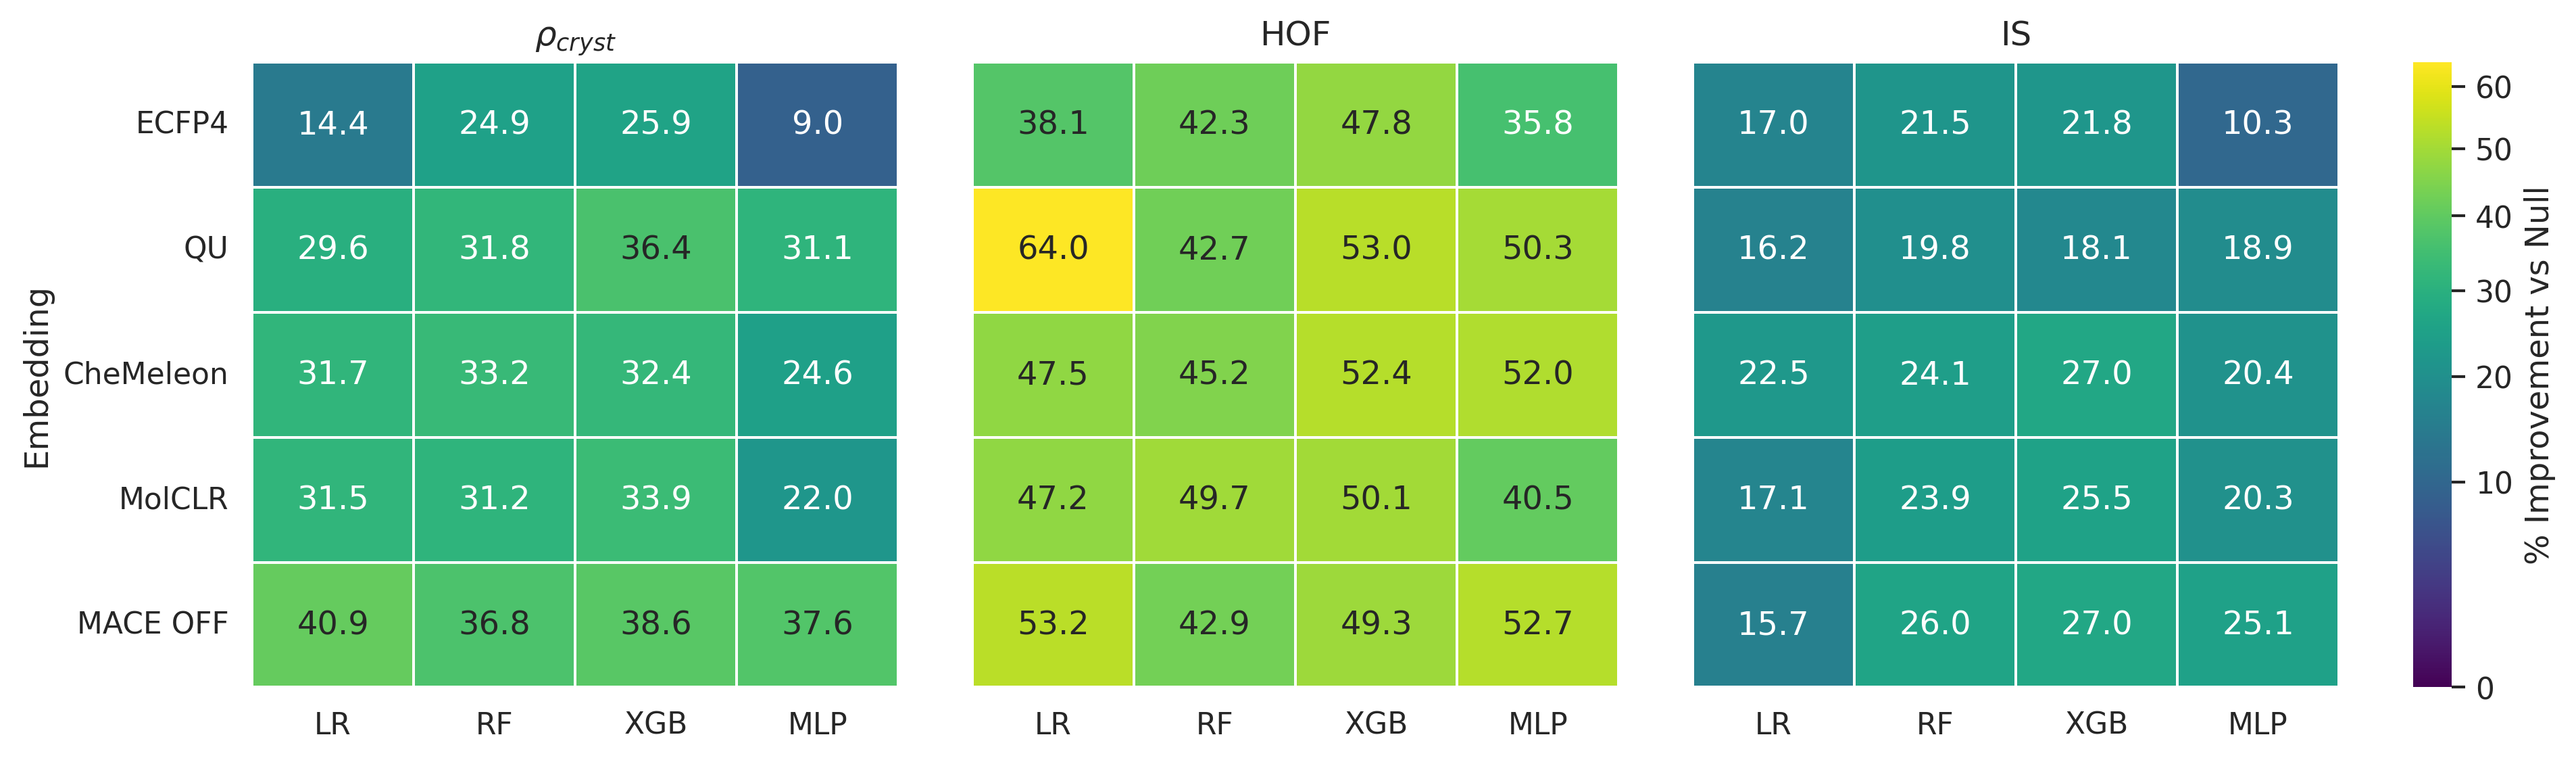

In [19]:
from matplotlib.colors import PowerNorm

sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)

datasets = seed_aggregated["dataset"].unique()
models = ["LR", "RF", "XGB", "MLP"]  # desired x-axis order
embeddings = seed_aggregated["embedding"].unique()

# Aggregate in case multiple seeds exist
plot_df = seed_aggregated.copy()

vmin = 0
vmax = 64
norm = PowerNorm(gamma=0.6, vmin=vmin, vmax=vmax)
n_panels = len(datasets)

fig = plt.figure(figsize=(14, 4), dpi=300, constrained_layout=False)
gs = fig.add_gridspec(1, n_panels + 1, width_ratios=[1] * n_panels + [0.06], wspace=0.15)

axes = [fig.add_subplot(gs[0, i]) for i in range(n_panels)]
cax = fig.add_subplot(gs[0, -1])

for i, (ax, ds) in enumerate(zip(axes, datasets)):
    sub = plot_df[plot_df["dataset"] == ds]

    heat = (
        sub.pivot(
            index="embedding",
            columns="model",
            values="pct_improvement_vs_null"
        )
        .reindex(index=embeddings, columns=models)
    )

    sns.heatmap(
        heat,
        ax=ax,
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
        norm=norm,
        annot=True,
        fmt=".1f",
        linewidths=0.5,
        linecolor="white",
        cbar=(i == 0),
        cbar_ax=cax if i == 0 else None,
        cbar_kws={"label": "% Improvement vs Null"}
    )

    ax.set_title(ds, fontsize=12)
    ax.set_xlabel("")
    ax.set_ylabel("Embedding" if i == 0 else "")
    if i > 0:
        ax.set_yticklabels([])  # hide y-tick labels for non-first panels

    ax.tick_params(axis="x", rotation=0)
    ax.tick_params(axis="y", rotation=0)

    # Publication-style cleanup
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

## evaluate penalties from harder splits

/tmp/ipykernel_60646/3773772991.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rand_grouped = rand_splits.groupby(["dataset", "embedding", "model"], as_index=False)["test_RMSE"].agg(["mean", "std"]).reset_index()
/tmp/ipykernel_60646/3773772991.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  scaff_grouped = scaff_splits.groupby(["dataset", "embedding", "model"], as_index=False)["test_RMSE"].agg(["mean", "std"]).reset_index()
/tmp/ipykernel_60646/3773772991.py:36: UserWarning: The palette list has more values (10) than needed (5), which may not be intended.
  sns.pointplot(
/tmp/ipykernel_60646/377377

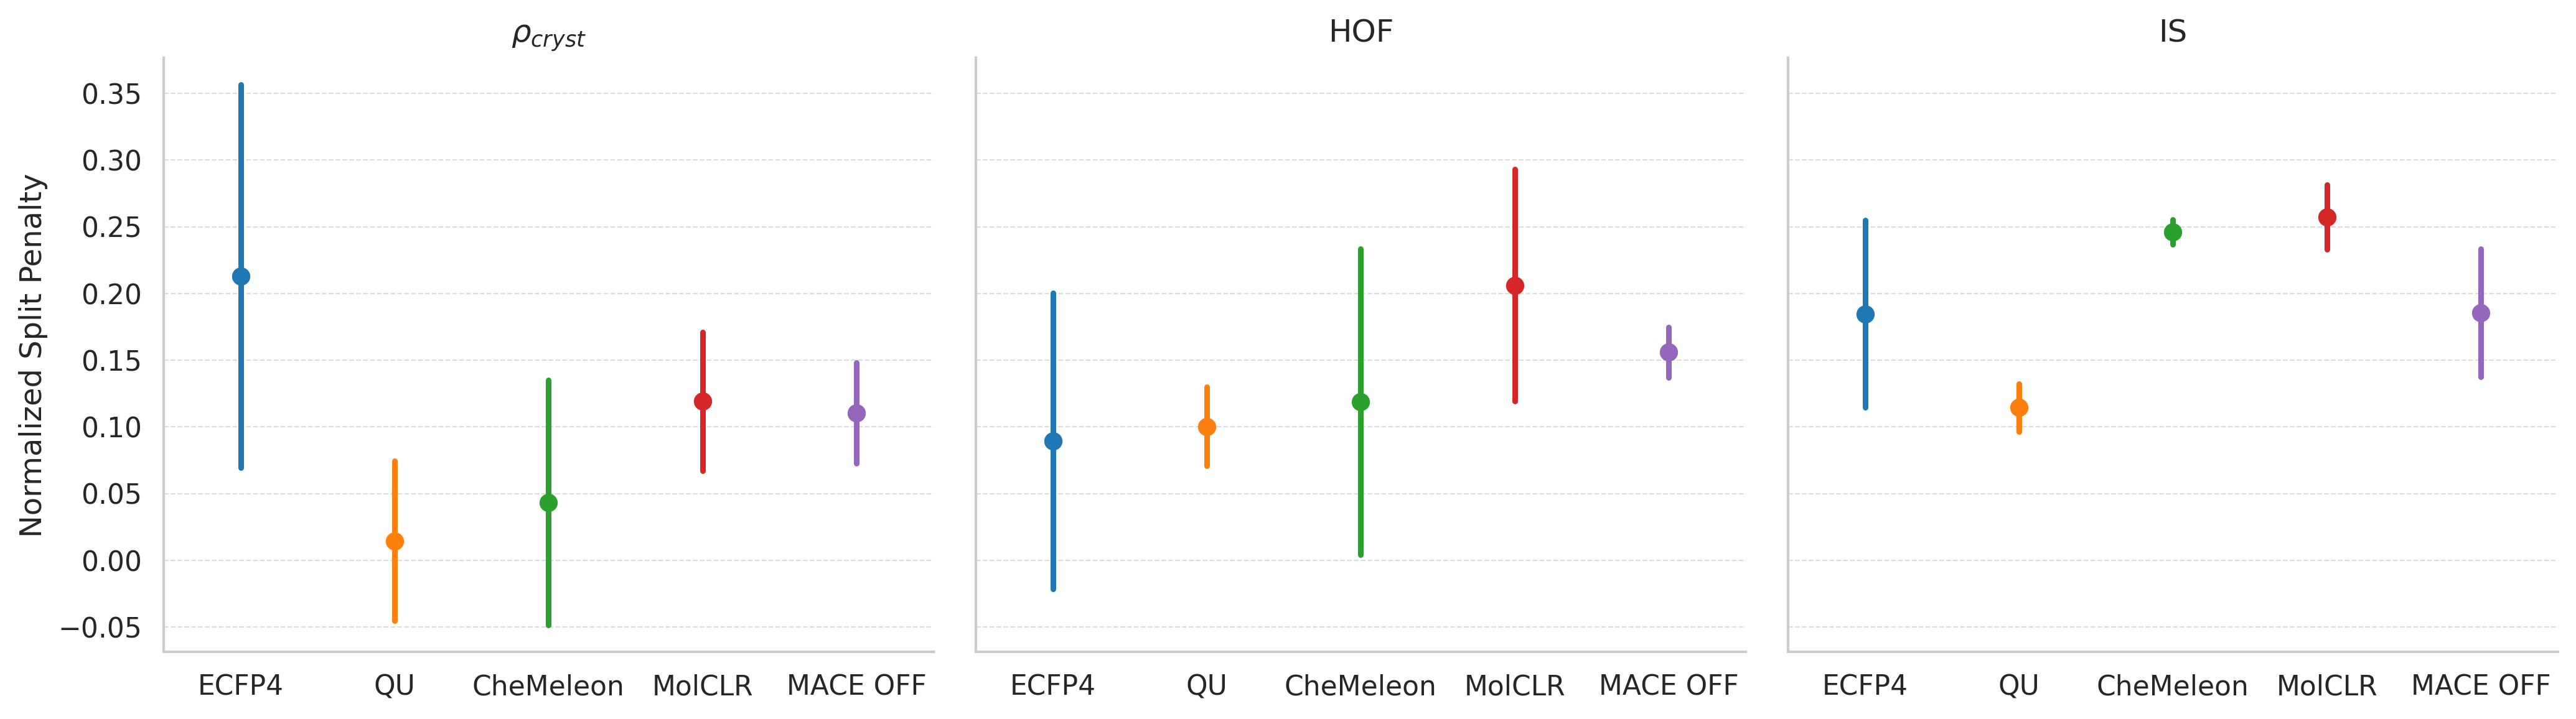

In [20]:
rand_splits = df[df["split_method"].str.contains("random_seed")].copy()
rand_grouped = rand_splits.groupby(["dataset", "embedding", "model"], as_index=False)["test_RMSE"].agg(["mean", "std"]).reset_index()

scaff_splits = df[df["split_method"].str.contains("cluster")].copy()
scaff_grouped = scaff_splits.groupby(["dataset", "embedding", "model"], as_index=False)["test_RMSE"].agg(["mean", "std"]).reset_index()

# --- compute normalized split penalty (robust merge vs relying on matching indices) ---
tmp = rand_grouped.merge(
    scaff_grouped[["dataset", "embedding", "model", "mean"]],
    on=["dataset", "embedding", "model"],
    suffixes=("_rand", "_scaff"),
)

tmp["split_penalty"] = tmp["mean_scaff"] - tmp["mean_rand"]
tmp["Normalized Split Penalty"] = tmp["split_penalty"] / tmp["mean_rand"]

# --- publication-style defaults ---
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
palette = sns.color_palette("tab10")  # colorblind-friendly, print-safe

datasets = desired_dataset_order
emb_order = desired_order_clean if "desired_order_clean" in globals() else list(tmp["embedding"].unique())

fig, axes = plt.subplots(
    1, len(datasets),
    figsize=(14, 4),
    sharey=True,
    dpi=300,
)

# If there's only 1 dataset, axes won't be iterable by default
axes = np.atleast_1d(axes)

for ax, ds in zip(axes, datasets):
    sub = tmp[tmp["dataset"] == ds]
    sns.pointplot(
        data=sub,
        x="embedding",
        y="Normalized Split Penalty",
        hue="embedding",
        order=emb_order,
        errorbar="sd",
        ax=ax,
        palette=palette,
        markers="o",
        linestyles=None,
    )

    ax.set_title(f"{ds}", fontsize=12)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
    ax.grid(True, axis="y", linestyle="--", linewidth=0.5, alpha=0.7)

    # Clean spines (publication style)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # Only keep ylabel on first plot
    if ax is axes[0]:
        ax.set_ylabel("Normalized Split Penalty")
    else:
        ax.set_ylabel("")

plt.tight_layout()
plt.show()

In [21]:
tmp.drop("index", axis=1).groupby(["dataset", "embedding"])[["Normalized Split Penalty"]].agg(["mean", "std"]).round(3)

/tmp/ipykernel_60646/4041978126.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tmp.drop("index", axis=1).groupby(["dataset", "embedding"])[["Normalized Split Penalty"]].agg(["mean", "std"]).round(3)


Normalized Split Penalty       
                                             mean    std
dataset        embedding                                
$\rho_{cryst}$ ECFP4                        0.213  0.144
               QU                           0.014  0.060
               CheMeleon                    0.043  0.092
               MolCLR                       0.119  0.052
               MACE OFF                     0.111  0.038
HOF            ECFP4                        0.089  0.111
               QU                           0.100  0.030
               CheMeleon                    0.119  0.115
               MolCLR                       0.206  0.087
               MACE OFF                     0.156  0.019
IS             ECFP4                        0.185  0.070
               QU                           0.114  0.018
               CheMeleon                    0.246  0.009
               MolCLR                       0.257  0.024
               MACE OFF                     0.186  0.048

# Deeper dive: parity and/or residual plots to show where models succeed/fail

In [22]:
# code gets outputted to root directory instead of corresponding output folder. 
# it is wrong and I should fix but haven't yet. 

# generate predictions for xgboost models and save to paraquet files
!python ../05_PY_SCRIPTS/generate_xgb_predictions.py

/home/andre/anaconda3/envs/chem/lib/python3.11/site-packages/xgboost/core.py:377: FutureWarning: Your system has an old version of glibc (< 2.28). We will stop supporting Linux distros with glibc older than 2.28 after **May 31, 2025**. Please upgrade to a recent Linux distro (with glibc >= 2.28) to use future versions of XGBoost.
Note: You have installed the 'manylinux2014' variant of XGBoost. Certain features such as GPU algorithms or federated learning are not available. To use these features, please upgrade to a recent Linux distro with glibc 2.28+, and install the 'manylinux_2_28' variant.
  warnings.warn(
Processed CD/xgboost/hq_descriptor/split=random_seed0_modelseed=0/ckpts/hq_descriptor_model=xgboost_seed=0.pkl
Processed CD/xgboost/hq_descriptor/split=random_seed0_modelseed=1/ckpts/hq_descriptor_model=xgboost_seed=1.pkl
Processed CD/xgboost/hq_descriptor/split=random_seed0_modelseed=2/ckpts/hq_descriptor_model=xgboost_seed=2.pkl
Processed CD/xgboost/hq_descriptor/split=random_s

In [23]:
parquet_path = "../07_OUTPUTS/20260625/deep_dive_xgb_predictions.parquet"  # adjust
predictions_df = pd.read_parquet(parquet_path)

renamed_embeddings = {
    "hq_descriptor": "QU",
    "maceoff_large": "MACE OFF",
}
predictions_df["embedding"] = predictions_df["embedding"].map(renamed_embeddings)


renamed_models = {"xgboost": "XGB"}
renamed_dataset = {"CD": r"$\rho_{cryst}$"}
predictions_df["dataset"] = predictions_df["dataset"].map(renamed_dataset).fillna(predictions_df["dataset"])

desired_dataset_order = [
    r"$\rho_{cryst}$",
    "HOF",
    "IS"
]
predictions_df["dataset"] = pd.Categorical(predictions_df["dataset"], categories=desired_dataset_order, ordered=True)

predictions_df

,dataset,embedding,split_seed,model_seed,compound_id,y_true,y_pred
0,$\rho_{cryst}$,QU,0,0,O=C(OCC([N+](=O)[O-])([N+](=O)[O-])[N+](=O)[O-...,1.851000,1.833033
1,$\rho_{cryst}$,QU,0,0,O=C(CCN(CCC(=O)OCC([N+](=O)[O-])([N+](=O)[O-])...,1.703000,1.706970
2,$\rho_{cryst}$,QU,0,0,O=[N+]([O-])c1cc([N+](=O)[O-])c(-c2c([N+](=O)[...,1.828000,1.738453
3,$\rho_{cryst}$,QU,0,0,O=[N+]([O-])c1ccc(CC([N+](=O)[O-])([N+](=O)[O-...,1.732000,1.705867
4,$\rho_{cryst}$,QU,0,0,Cn1nc([N+](=O)[O-])c(Nc2c([N+](=O)[O-])cc([N+]...,1.746000,1.755874
...,...,...,...,...,...,...,...
15995,IS,MACE OFF,4,4,O=[N+]([O-])c1cc([N+](=O)[O-])c(C=Cc2c([N+](=O...,2.257065,1.641250
15996,IS,MACE OFF,4,4,Nc1nc(N)n2nc(N)c([N+](=O)[O-])c2n1,3.688880,4.001578
15997,IS,MACE OFF,4,4,Cc1c([N+](=O)[O-])cc([N+](=O)[O-])c(C)c1[N+](=...,0.693147,0.926044
15998,IS,MACE OFF,4,4,Cc1c([N+](=O)[O-])c(C)c([N+](=O)[O-])c(O)c1[N+...,0.634718,1.383015


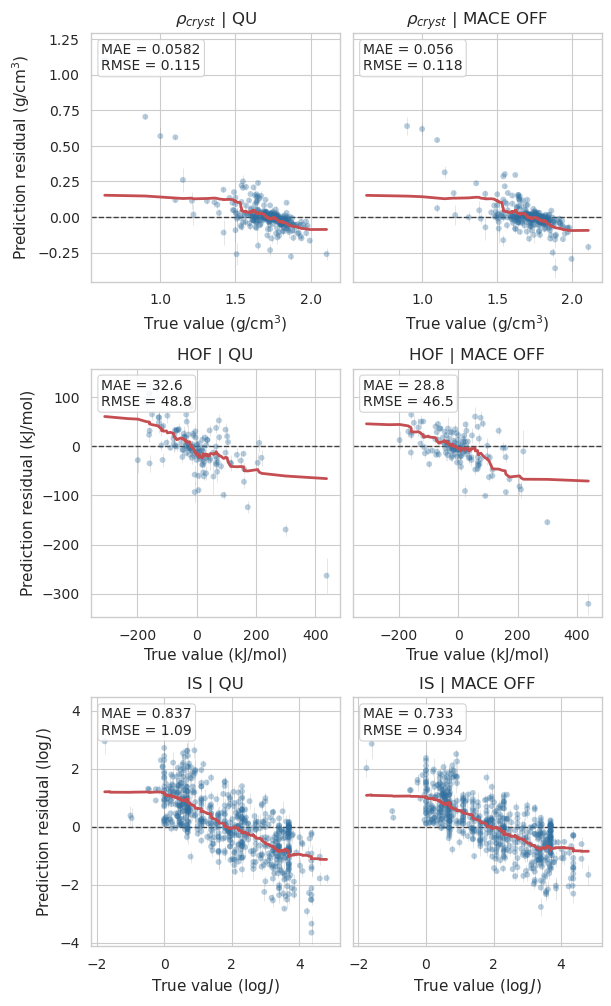

In [35]:
import importlib
import xgb_prediction_plots
importlib.reload(xgb_prediction_plots)

from xgb_prediction_plots import (
    aggregate_seed_predictions,
    plot_residual_grid,
    plot_parity_grid,
)

predictions_agg = aggregate_seed_predictions(predictions_df)
predictions_agg.head()

fig = plot_residual_grid(predictions_df, show_pred_std=True, use_aggregated=True, figsize=(6, 10))

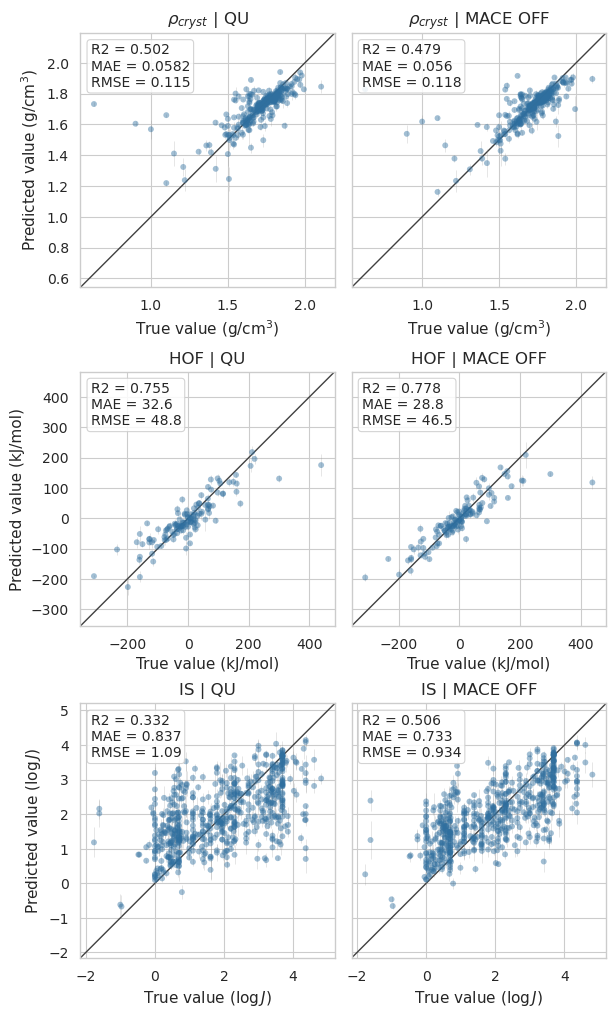

In [34]:
fig = plot_parity_grid(
    predictions_df,
    use_aggregated=True,
    color_by=None,
    show_pred_std=True,
    figsize=(6, 10),
)

## Look up coefficients for the linear models -- eg strength of correlations with descriptors. 

In [26]:
from IPython.display import display
import joblib
OUTPUT_ROOT = Path("../07_OUTPUTS/20260625")

DESCRIPTORS = [
    "rotbonds", "heteroatoms", "totrings", "aromrings", "alirings",
    "VSA8", "VSA5", "TPSA", "MolWt", "numC", "numN", "numO",
    "OxBal", "hbondratio", "kmf", "class1", "class2",
]

checkpoint_paths = sorted(
    OUTPUT_ROOT.glob("*/linear/hq_descriptor/split=*/ckpts/*.pkl")
)

if not checkpoint_paths:
    raise FileNotFoundError(
        f"No QU linear checkpoints found under {OUTPUT_ROOT.resolve()}"
    )

enet_models = {}
records = []

for checkpoint_path in checkpoint_paths:
    artifact = joblib.load(checkpoint_path)
    pipeline = artifact["best_estimator"]
    enet = pipeline.named_steps["model"]

    if len(enet.coef_) != len(DESCRIPTORS):
        raise ValueError(
            f"{checkpoint_path}: found {len(enet.coef_)} coefficients "
            f"but {len(DESCRIPTORS)} descriptor names."
        )

    split = artifact["split"]
    split_family = "cluster" if split.startswith("cluster_") else "random"
    split_id = int(re.search(r"(\d+)$", split).group(1))
    model_seed = int(artifact["seed"])

    key = (
        artifact["dataset"],
        split_family,
        split_id,
        model_seed,
    )
    enet_models[key] = enet

    records.extend(
        {
            "dataset": artifact["dataset"],
            "split_family": split_family,
            "split_id": split_id,
            "model_seed": model_seed,
            "descriptor": descriptor,
            "coefficient": float(coefficient),
        }
        for descriptor, coefficient in zip(DESCRIPTORS, enet.coef_)
    )

coefficient_runs = pd.DataFrame(records)

coefficient_summary = (
    coefficient_runs
    .groupby(
        ["dataset", "split_family", "descriptor"],
        as_index=False,
        sort=False,
    )
    .agg(
        mean_coefficient=("coefficient", "mean"),
        std_coefficient=("coefficient", "std"),
        n_models=("coefficient", "size"),
    )
)

coefficient_summary["mean ± std"] = coefficient_summary.apply(
    lambda row: (
        f'{row["mean_coefficient"]:.4g} ± '
        f'{row["std_coefficient"]:.4g}'
    ),
    axis=1,
)

print(f"Loaded {len(enet_models)} ElasticNet models.")
display(coefficient_summary)

Loaded 150 ElasticNet models.


,dataset,split_family,descriptor,mean_coefficient,std_coefficient,n_models,mean ± std
0,CD,cluster,rotbonds,-0.020824,0.018702,25,-0.02082 ± 0.0187
1,CD,cluster,heteroatoms,0.028203,0.036806,25,0.0282 ± 0.03681
2,CD,cluster,totrings,0.038933,0.010366,25,0.03893 ± 0.01037
3,CD,cluster,aromrings,0.029885,0.005226,25,0.02988 ± 0.005226
4,CD,cluster,alirings,0.003204,0.009664,25,0.003204 ± 0.009664
...,...,...,...,...,...,...,...
97,IS,random,OxBal,-0.706730,0.054105,25,-0.7067 ± 0.0541
98,IS,random,hbondratio,0.141265,0.026792,25,0.1413 ± 0.02679
99,IS,random,kmf,-0.690874,0.123083,25,-0.6909 ± 0.1231
100,IS,random,class1,0.319229,0.047374,25,0.3192 ± 0.04737


In [27]:
enet = enet_models[("CD", "random", 0, 0)]
enet.coef_

array([-0.03045448,  0.0105138 ,  0.03817758,  0.03110052,  0.00197058,
       -0.04448806, -0.00019462,  0.03144349,  0.00862808,  0.0005747 ,
       -0.00691184,  0.00961881,  0.07121735,  0.01810289, -0.07147356,
        0.03724454, -0.01283668])

In [28]:
coefficient_summary.query(
    "dataset == 'CD' and split_family == 'random'"
)

,dataset,split_family,descriptor,mean_coefficient,std_coefficient,n_models,mean ± std
17,CD,random,rotbonds,-0.021247,0.028882,25,-0.02125 ± 0.02888
18,CD,random,heteroatoms,0.020952,0.031303,25,0.02095 ± 0.0313
19,CD,random,totrings,0.035828,0.004578,25,0.03583 ± 0.004578
20,CD,random,aromrings,0.028896,0.006020,25,0.0289 ± 0.00602
21,CD,random,alirings,0.002466,0.002726,25,0.002466 ± 0.002726
22,CD,random,VSA8,-0.054086,0.009574,25,-0.05409 ± 0.009574
23,CD,random,VSA5,-0.001889,0.003023,25,-0.001889 ± 0.003023
24,CD,random,TPSA,0.091462,0.099463,25,0.09146 ± 0.09946
25,CD,random,MolWt,0.037436,0.064488,25,0.03744 ± 0.06449
26,CD,random,numC,0.004198,0.018596,25,0.004198 ± 0.0186


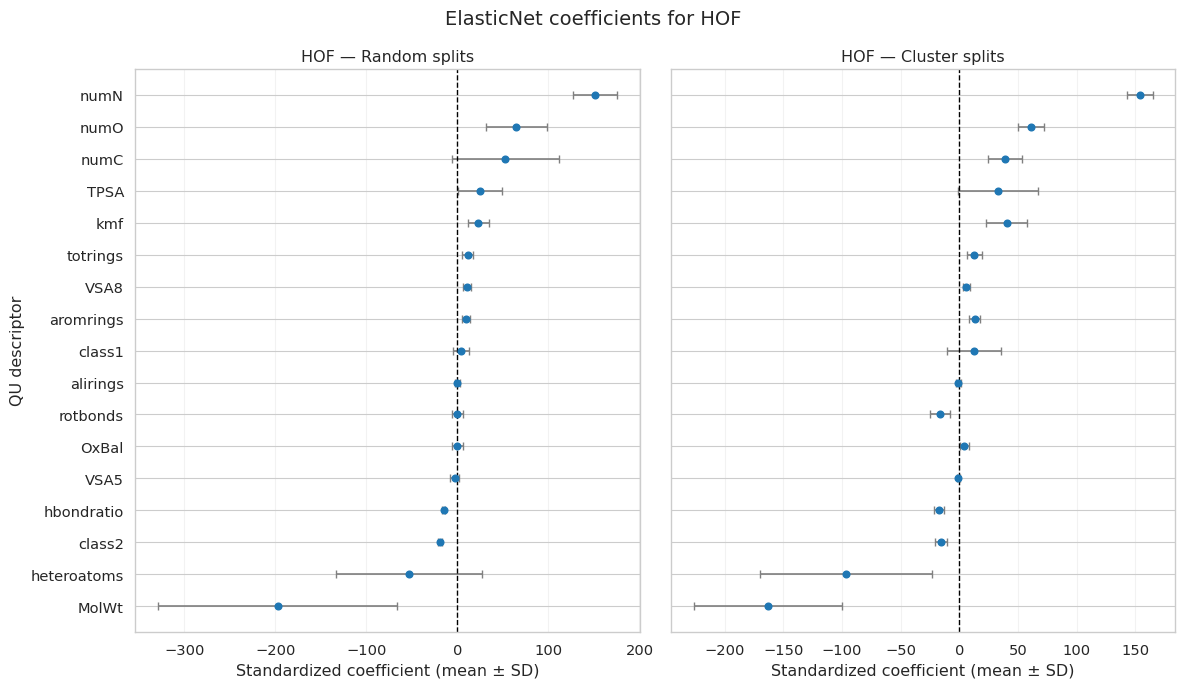

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

hof = coefficient_summary.query("dataset == 'HOF'").copy()

fig, axes = plt.subplots(1, 2, figsize=(12, 7), sharey=True)

for ax, split_family in zip(axes, ["random", "cluster"]):
    plot_df = (
        hof.query("split_family == @split_family")
        .sort_values("mean_coefficient")
    )

    ax.errorbar(
        plot_df["mean_coefficient"],
        plot_df["descriptor"],
        xerr=plot_df["std_coefficient"],
        fmt="o",
        capsize=3,
        color="tab:blue",
        ecolor="grey",
    )

    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.set_title(f"HOF — {split_family.capitalize()} splits")
    ax.set_xlabel("Standardized coefficient (mean ± SD)")
    ax.grid(axis="x", alpha=0.25)

axes[0].set_ylabel("QU descriptor")
axes[1].set_ylabel("")

fig.suptitle("ElasticNet coefficients for HOF", fontsize=14)
plt.tight_layout()
plt.show()

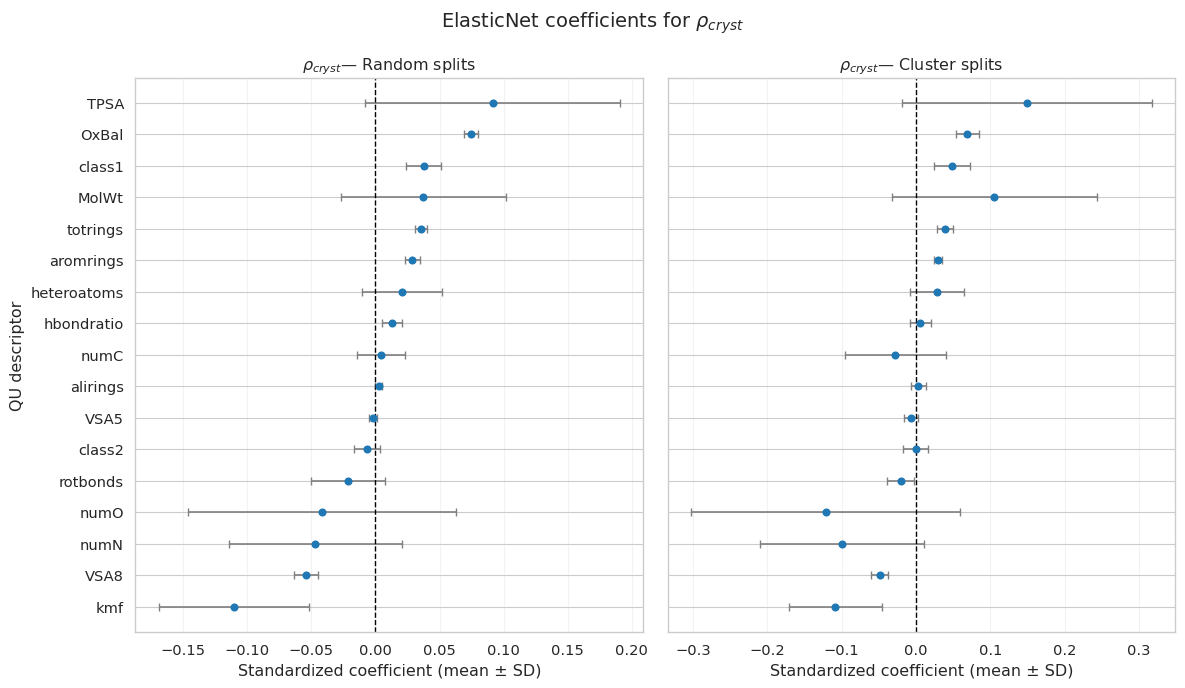

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

hof = coefficient_summary.query("dataset == 'CD'").copy()

fig, axes = plt.subplots(1, 2, figsize=(12, 7), sharey=True)

for ax, split_family in zip(axes, ["random", "cluster"]):
    plot_df = (
        hof.query("split_family == @split_family")
        .sort_values("mean_coefficient")
    )

    ax.errorbar(
        plot_df["mean_coefficient"],
        plot_df["descriptor"],
        xerr=plot_df["std_coefficient"],
        fmt="o",
        capsize=3,
        color="tab:blue",
        ecolor="grey",
    )

    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.set_title(r"$\rho_{cryst}$" + f"— {split_family.capitalize()} splits")
    ax.set_xlabel("Standardized coefficient (mean ± SD)")
    ax.grid(axis="x", alpha=0.25)

axes[0].set_ylabel("QU descriptor")
axes[1].set_ylabel("")

fig.suptitle(r"ElasticNet coefficients for $\rho_{cryst}$", fontsize=14)
plt.tight_layout()
plt.show()

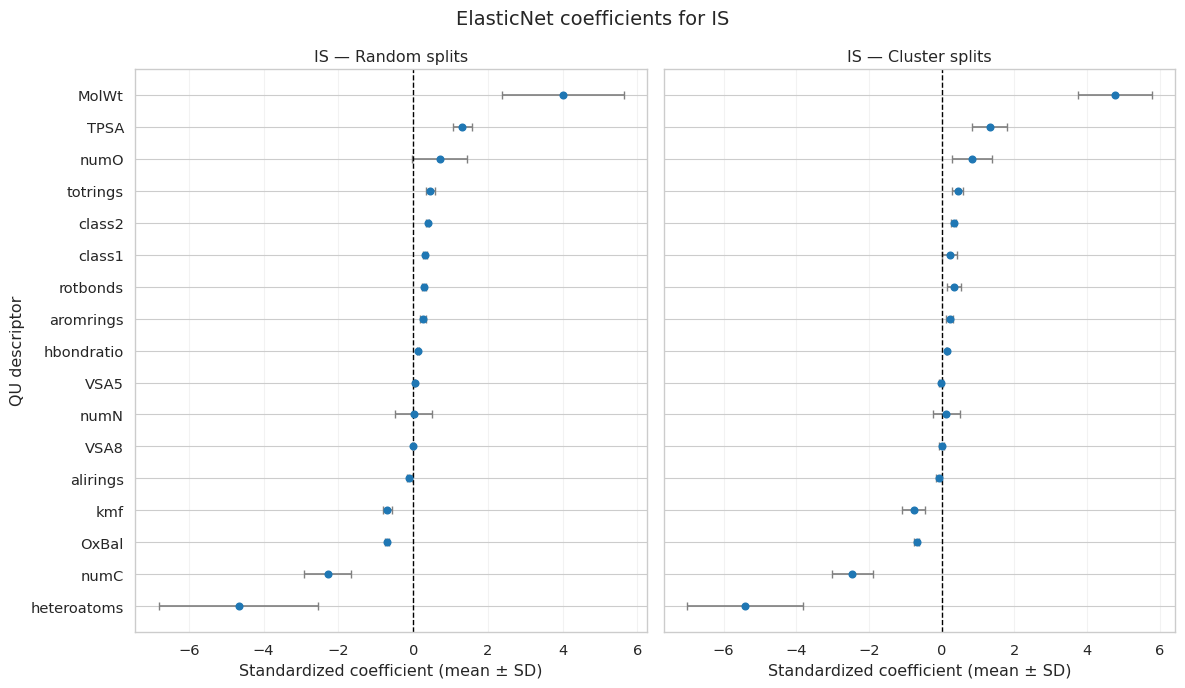

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

hof = coefficient_summary.query("dataset == 'IS'").copy()

fig, axes = plt.subplots(1, 2, figsize=(12, 7), sharey=True)

for ax, split_family in zip(axes, ["random", "cluster"]):
    plot_df = (
        hof.query("split_family == @split_family")
        .sort_values("mean_coefficient")
    )

    ax.errorbar(
        plot_df["mean_coefficient"],
        plot_df["descriptor"],
        xerr=plot_df["std_coefficient"],
        fmt="o",
        capsize=3,
        color="tab:blue",
        ecolor="grey",
    )

    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.set_title(f"IS — {split_family.capitalize()} splits")
    ax.set_xlabel("Standardized coefficient (mean ± SD)")
    ax.grid(axis="x", alpha=0.25)

axes[0].set_ylabel("QU descriptor")
axes[1].set_ylabel("")

fig.suptitle("ElasticNet coefficients for IS", fontsize=14)
plt.tight_layout()
plt.show()